# Fair Aid QAOA - Track 2 Submission

**Question: How can we select aid projects while making the budget, benefits, and allocation priorities explicit?**

Consider a community aid team responding after a disaster. It has three standard budget units and must select three of six projects. A–C represent established service locations; D–F serve underserved groups. Project benefits, overlaps, and priority scores are entirely synthetic; actual needs and beneficiary counts are unknown. This is a simplified model of a real type of decision, not an empirical study of a particular disaster.

This version adds **a comparison of complete X and XY QAOA variants, classical greedy and local-swap methods, score perturbations, and a policy comparison with minimum service-project quotas**. The original [24-run introductory experiment](Fair_Aid_QAOA.ipynb) is retained. This notebook uses a separate 80-run comparison experiment.

This project addresses [official Track 2](https://github.com/sandraalhames/Qompute-2026#track-2-optimizing-for-people). Start with the [project README](README.md) for review; see [submission/README.md](submission/README.md) for the recording outline and submission tasks. The project repository is [gengx-prog/qompute-2026-fair-aid-qaoa](https://github.com/gengx-prog/qompute-2026-fair-aid-qaoa).

## 1. Load Traceable Experiment Results

By default, the notebook loads completed experiment results and verifies the SHA256 hashes of the input data and computational source files. Stale results trigger an error. Set `RERUN_EXPERIMENTS=True` to recompute all 80 runs; a missing result manifest also triggers recomputation. Every display cell below can be executed from the beginning. Package versions and the quantum experiment timestamp are recorded in the manifest.

In [1]:
from pathlib import Path
import sys, json, hashlib, html
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

cwd = Path.cwd().resolve()
PROJECT_DIR = next((p for p in (cwd, cwd / "fair_aid", cwd / "Track 2" / "fair_aid")
                    if (p / "benchmark.py").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Run from the repository root, Track 2, or fair_aid directory.")
sys.path.insert(0, str(PROJECT_DIR))
from allocation import load_problem
from benchmark import run_benchmark
from plots import read_rows, is_true, plot_tradeoff
from plot_comparison import plot_mixer_comparison, plot_score_stability, generate_comparison_figures

RERUN_EXPERIMENTS = False
RESULTS_DIR = PROJECT_DIR / "results" / "comparison"
if RERUN_EXPERIMENTS or not (RESULTS_DIR / "manifest.json").exists():
    run_benchmark(RESULTS_DIR)
manifest = json.loads((RESULTS_DIR / "manifest.json").read_text(encoding="utf-8"))
for filename, expected in manifest["sha256"].items():
    actual = hashlib.sha256((PROJECT_DIR / filename).read_bytes()).hexdigest()
    if actual != expected:
        raise ValueError(f"Source or data changed: {filename}. Set RERUN_EXPERIMENTS=True and run again.")
assert manifest["runs"] == 80 and manifest["seeds"] == [11, 29, 47, 71, 97]
assert manifest["maxiter"] == 300 and manifest["shots_per_run"] == 2048
assert manifest["mixers"] == ["x", "xy"]
summary = read_rows(RESULTS_DIR / "summary.csv")
grouped = read_rows(RESULTS_DIR / "grouped_summary.csv")
exact = read_rows(RESULTS_DIR / "exact_solutions.csv")
classical = read_rows(RESULTS_DIR / "classical_baselines.csv")
stability = read_rows(RESULTS_DIR / "policy_stability.csv")
selections = read_rows(RESULTS_DIR / "selection_stability.csv")
quotas = read_rows(RESULTS_DIR / "quota_policy.csv")
assert len(summary) == 80

def table(rows, columns):
    header = "".join(f"<th>{html.escape(label)}</th>" for _, label in columns)
    body = []
    for row in rows:
        values = []
        for key, _ in columns:
            value = row.get(key, "")
            try:
                value = f"{float(value):.4g}"
            except (ValueError, TypeError):
                pass
            values.append(f"<td>{html.escape(str(value))}</td>")
        body.append("<tr>" + "".join(values) + "</tr>")
    display(HTML("<table><thead><tr>" + header + "</tr></thead><tbody>" + "".join(body) + "</tbody></table>"))

print("Verified experiment:", manifest["generated_at_utc"])
print("Quantum experiment packages:", manifest["packages"])
print("80 runs; ideal simulation; results read with verified source hashes.")

Verified experiment: 2026-10-12T08:39:32.237308+00:00
Quantum experiment packages: {'qiskit': '2.5.2', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'nbformat': '5.11.1', 'nbclient': '0.11.0'}
80 runs; ideal simulation; results read with verified source hashes.


In [2]:
xy_runs = [r for r in summary if r["mixer"] == "xy"]
x_runs = [r for r in summary if r["mixer"] == "x"]
xy_min_feasible = min(float(r["feasible_probability"]) for r in xy_runs)
non_converged = sum(not is_true(r["optimizer_success"]) for r in summary)
xy_groups = [r for r in grouped if r["mixer"] == "xy"]
above_random = sum(float(r["optimal_probability_mean"]) > 0.05 + 1e-9 for r in xy_groups)
display(Markdown(
    f"**Results from this experiment:** the lowest feasible probability across 40 XY runs was {xy_min_feasible:.6%}. "
    f"Of the eight XY weight/depth configurations, {above_random} had a mean optimal probability above the 5% uniform-feasible baseline. "
    f"Across all 80 runs, {non_converged} did not report optimizer convergence; all are retained. "
    "Both the initial state and mixer change, so differences cannot be attributed to the mixer alone. A higher feasibility rate is not evidence of quantum advantage."))

**Results from this experiment:** the lowest feasible probability across 40 XY runs was 100.000000%. Of the eight XY weight/depth configurations, 3 had a mean optimal probability above the 5% uniform-feasible baseline. Across all 80 runs, 48 did not report optimizer convergence; all are retained. Both the initial state and mixer change, so differences cannot be attributed to the mixer alone. A higher feasibility rate is not evidence of quantum advantage.

## 2. Scenario, Cost Function, and Validation of Every Basis State

The organization sets the budget and candidate list. Field teams and representatives of affected groups should jointly assess needs and barriers to services. The optimizer supplies comparable candidate allocations, while accountable people make the final decision. This prototype has no real needs data, so priority scores represent policy preferences open to discussion.

Each project costs one unit, with $x_i\in\{0,1\}$. Net benefit $B$ deducts overlap for each project pair, and $E$ is the priority score.

$$U_w(x)=\underbrace{\sum_i b_i x_i-\sum_{i<j}o_{ij}x_i x_j}_{B(x)}+w\underbrace{\sum_i e_i x_i}_{E(x)},\qquad \sum_i x_i=3.$$
$$C(x)=-U_w(x)+A(\sum_i x_i-3)^2,\quad A=20.$$

The QUBO coefficients are $c=9A$, $a_i=-(b_i+we_i)-5A$, and $Q_{ij}=o_{ij}+2A$. Substituting $x_i=(I-Z_i)/2$ gives the Hamiltonian coefficients:

$$h_i=-a_i/2-\sum_{j\ne i}Q_{ij}/4,\quad J_{ij}=Q_{ij}/4,\quad h_0=c+\sum_i a_i/2+\sum_{i<j}Q_{ij}/4.$$

In the symmetric sum, $Q_{ij}$ refers to an unordered project pair; the code stores the upper triangle. Project A maps to qubit 0, the rightmost bit in the bitstring.
Let $g_i=b_i+we_i$. Repairing an over- or under-selected allocation by one project increases unpenalized cost by at most $M=\max_i\{g_i,\sum_j o_{ij}-g_i\}$ and reduces the squared violation by at least one. Thus $A>M$ guarantees feasibility of every exact ground-state solution. For $w\in[0,2]$, $M\le13.5$. This proof does not guarantee that every X-QAOA sample is feasible.

In [3]:
problem = load_problem()
table(read_rows(PROJECT_DIR / "data" / "projects.csv"),
      [("id", "Project"), ("name", "Project name"), ("benefit", "Benefit score"), ("equity", "Priority score"), ("unit_cost", "Cost")])
checks = []
for weight in manifest["weights"]:
    direct = []
    for state in range(64):
        bits = [(state >> i) & 1 for i in range(6)]
        direct.append(-sum((problem.benefit[i] + weight * problem.equity[i]) * bits[i] for i in range(6))
                      + sum(problem.overlap[i,j] * bits[i] * bits[j] for i in range(6) for j in range(i+1,6))
                      + 20 * (sum(bits)-3)**2)
    matrix = problem.hamiltonian(weight, 20).to_matrix()
    np.testing.assert_allclose(matrix, np.diag(direct), atol=1e-10, rtol=0)
    checks.append({"weight": weight, "states": 64, "error": float(np.abs(matrix-np.diag(direct)).max())})
table(checks, [("weight", "w"), ("states", "Independently checked basis states"), ("error", "Maximum absolute error")])

Project,Project name,Benefit score,Priority score,Cost
A,Central food hub,9,0,1
B,Established distribution center,8.5,0.5,1
C,Transit-accessible supply point,7,1,1
D,Mobile outreach team,6.5,2,1
E,Remote neighborhood delivery,6,3,1
F,Accessible home delivery,5.5,4,1


w,Independently checked basis states,Maximum absolute error
0,64,3.73e-14
0.5,64,3.73e-14
1,64,3.73e-14
2,64,3.73e-14


## 3. Comparing the Two QAOA Variants

**Original X variant:** start from $|+\rangle^{\otimes6}$, use the conventional X mixer, and include the squared budget penalty.

**XY variant:** the initial state has equal amplitudes on all 20 feasible allocations, without consulting objective scores or known optima. Apply $RXX(\beta)RYY(\beta)$ sequentially along ring edges $(0,1),(1,2),\ldots,(5,0)$. Each complete gate pair exchanges amplitudes only between $|01\rangle$ and $|10\rangle$, preserving the selected project count. This ordered gate product with one shared beta defines the mixer; it is not the exact exponential of the sum of all ring interactions. The approach follows the [alternating operator framework of Hadfield et al.](https://arxiv.org/abs/1709.03489).

Both variants use Qiskit `QAOAAnsatz`, `StatevectorEstimator`, COBYLA, and `StatevectorSampler`. They share $A=20$, the same Pauli coefficient scaling, four weights, p=1/2, five seeds, a limit of 300 objective calls, and 2,048 shots. Training removes the constant term; reporting restores the original cost scale.

The initial state and mixer **change together**, so this compares complete algorithm variants. Equal objective-call budgets do not imply equal quantum resources. XY's generic `StatePreparation` uses an explicit vector of $2^n$ amplitudes and is not a scalable Dicke-state preparation method. The gate counts include its preparation cost. Compilation uses logical h/rx/rz/cx gates with all-to-all connectivity, without device routing or noise.

The figure shows exact single-shot probabilities from the final state. Error bars span the minimum and maximum across five initializations and **are not confidence intervals**. Sampled frequencies are recorded separately in the CSV. Infeasible outcomes remain in the denominator of total probabilities.

Mixer,w,p,Mean feasible probability,Mean optimal probability,Mean conditional regret,Mean CX count,Converged runs / 5
x,0,1,0.3822,0.01946,2.253,30,4
x,0,2,0.3025,0.01575,2.289,60,1
x,0.5,1,0.3144,0.0156,1.101,30,5
x,0.5,2,0.4375,0.02262,1.084,60,4
x,1,1,0.314,0.0153,1.332,30,4
x,1,2,0.4711,0.02539,1.281,60,3
x,2,1,0.36,0.0157,4.597,30,5
x,2,2,0.5479,0.02529,5.391,60,3
xy,0,1,1,0.1135,1.699,111,0
xy,0,2,1,0.1087,1.61,165,0


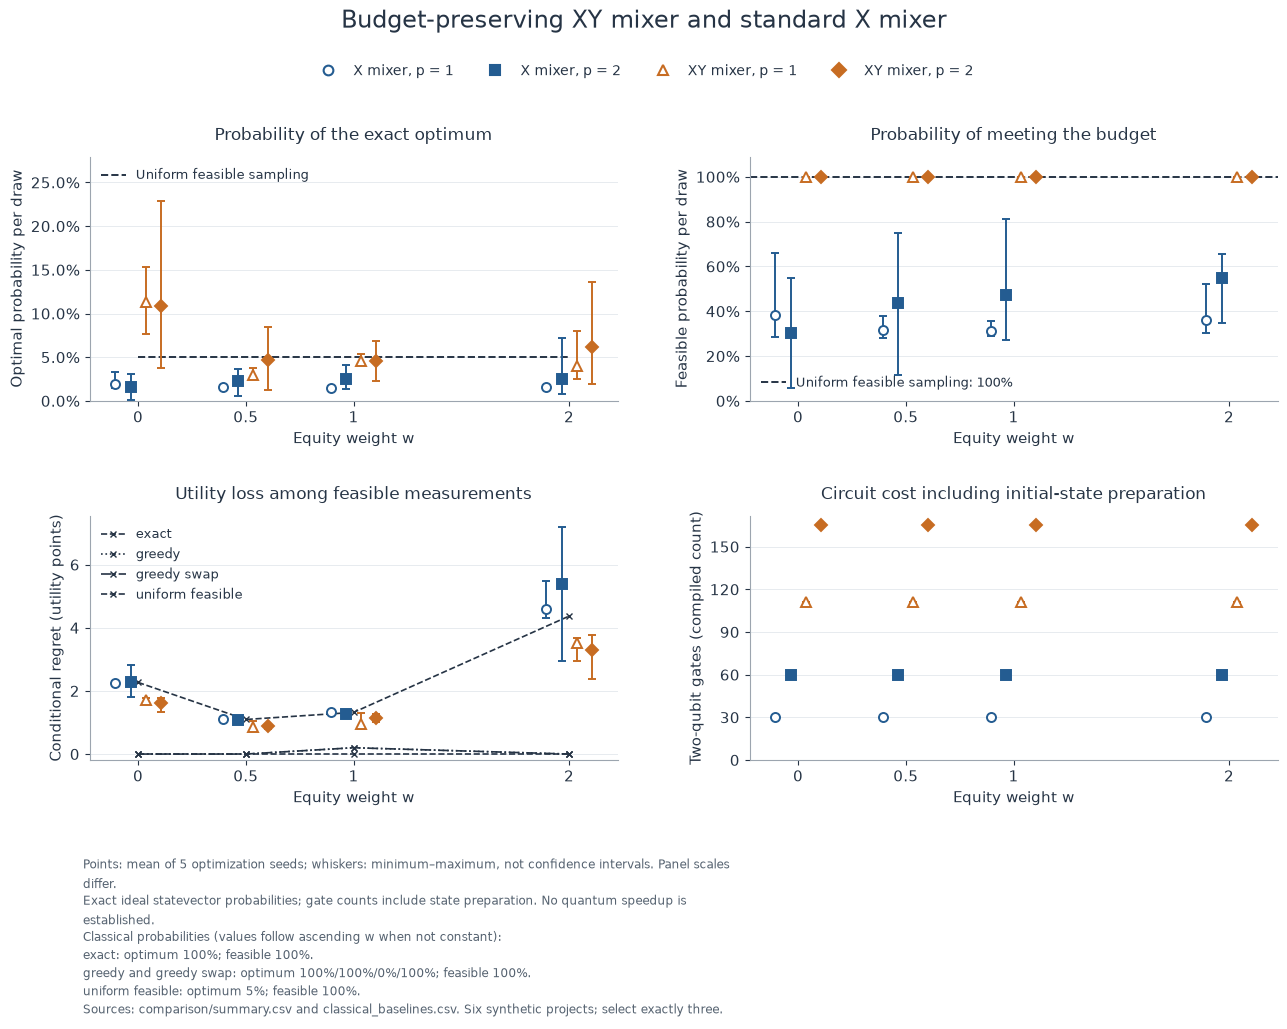

In [4]:
table(grouped, [("mixer", "Mixer"), ("weight", "w"), ("depth", "p"),
                ("feasible_probability_mean", "Mean feasible probability"), ("optimal_probability_mean", "Mean optimal probability"),
                ("conditional_regret_mean", "Mean conditional regret"), ("two_qubit_gates_mean", "Mean CX count"),
                ("converged", "Converged runs / 5")])
plot_mixer_comparison(summary, classical)
plt.show()

## 4. Classical Methods and Policy Tradeoffs

Classical baselines include greedy selection by maximum marginal utility, greedy-swap with improving one-for-one exchanges, exhaustive enumeration, and uniform feasible sampling. Greedy construction and local exchanges do not consult known optima. Good performance on this instance does not establish optimality at arbitrary scales.

A single uniform feasible sample finds the unique optimum with probability 5%, and exhaustive search covers only 64 states. Finding an optimum once among 2,048 samples is weak evidence and cannot establish speedup. The random classical strategy below is an exact distributional reference; the other three methods produce deterministic outputs. Utilities at different $w$ incorporate different preferences, so a larger objective score alone does not establish social improvement.

w,Classical method,Selection,Utility,Regret,Optimal probability,Reference objective evaluations
0,greedy,"A,B,D",22.1,0,1,15
0,greedy_swap,"A,B,D",22.1,0,1,24
0,exact,"A,B,D",22.1,0,1,64
0,uniform_feasible,uniform over all feasible sets,19.83,2.27,0.05,20
0.5,greedy,"A,B,F",23.55,0,1,15
0.5,greedy_swap,"A,B,F",23.55,0,1,24
0.5,exact,"A,B,F",23.55,0,1,64
0.5,uniform_feasible,uniform over all feasible sets,22.45,1.095,0.05,20
1,greedy,"B,D,F",26.2,0.2,0,15
1,greedy_swap,"B,D,F",26.2,0.2,0,24


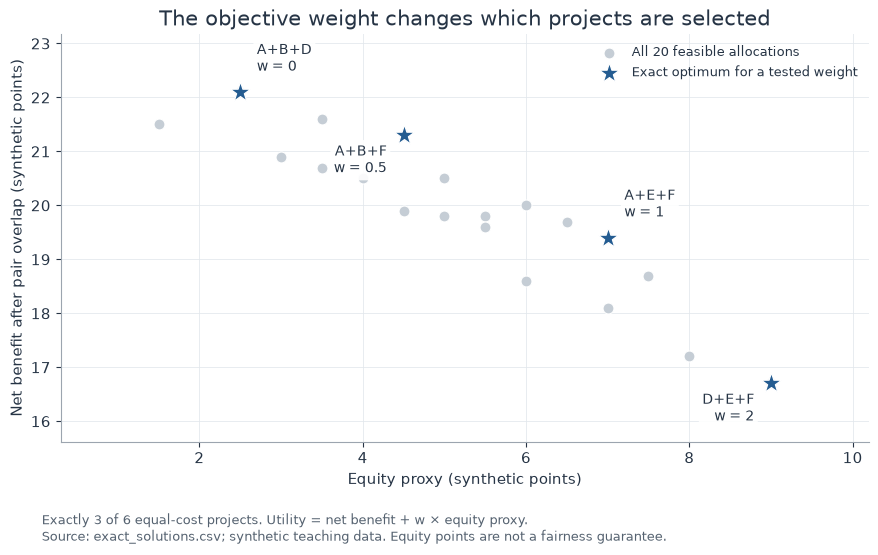

In [5]:
table(classical, [("weight", "w"), ("method", "Classical method"), ("selected", "Selection"),
                  ("utility", "Utility"), ("regret", "Regret"), ("optimal_probability", "Optimal probability"),
                  ("objective_evaluations", "Reference objective evaluations")])
plot_tradeoff(exact)
plt.show()

## 5. Who Remains Selected When Scores Change by up to 10%?

Using fixed seed 2026, generate 500 stress scenarios by multiplying each benefit score, priority score, and project-pair overlap by independent $Uniform[0.9,1.1]$ factors. Zero scores remain zero. The same scenarios are reused at each weight, and classical enumeration solves each scenario again. When optima are tied, project inclusion credit is split equally across the tied solutions.

These are **chosen, independent perturbation scenarios**, not statistical confidence intervals or an empirical error model. They omit correlations between scoring errors. The frequency with which the original allocation remains optimal measures stability under this stress test; project inclusion frequency is not population coverage. Raw perturbed inputs are in `perturbed_inputs.json`, and scenario-level winners and regrets are in `sensitivity_details.csv`.

w,Original optimum,Optimality retention rate,Mean original-allocation regret,Maximum original-allocation regret
0,"A,B,D",0.706,0.06763,0.8863
0.5,"A,B,F",0.312,0.2987,1.525
1,"A,E,F",0.422,0.3456,2.227
2,"D,E,F",0.932,0.01614,0.6621


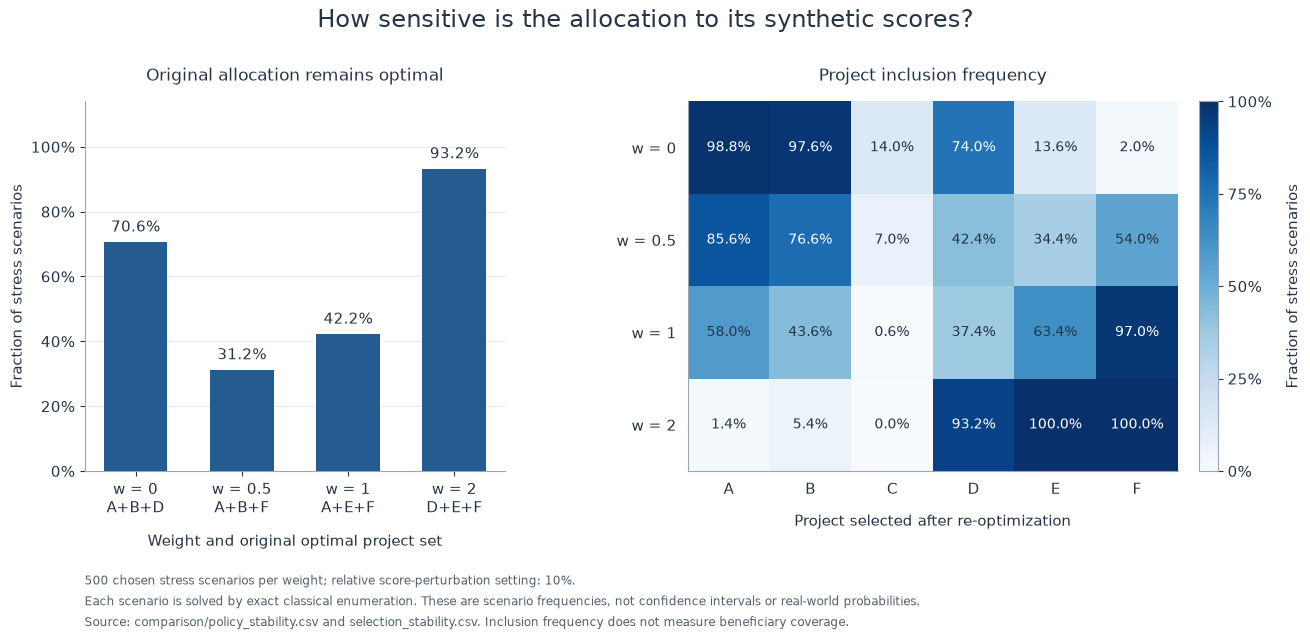

**This stress test:** the original allocation A,B,F at w=0.5 was least stable, remaining optimal in 31.2% of scenarios. When the evidence behind scores is uncertain, this supports presenting several candidate allocations and validating critical inputs first.

In [6]:
table(stability, [("weight", "w"), ("baseline_selected", "Original optimum"),
                  ("baseline_still_optimal_rate", "Optimality retention rate"), ("mean_baseline_regret", "Mean original-allocation regret"),
                  ("max_baseline_regret", "Maximum original-allocation regret")])
plot_score_stability(stability, selections)
plt.show()
least_stable = min(stability, key=lambda r: float(r["baseline_still_optimal_rate"]))
display(Markdown(f"**This stress test:** the original allocation {least_stable['baseline_selected']} "
                 f"at w={float(least_stable['weight']):g} was least stable, remaining optimal in "
                 f"{float(least_stable['baseline_still_optimal_rate']):.1%} of scenarios. "
                 "When the evidence behind scores is uncertain, this supports presenting several candidate allocations and validating critical inputs first."))

## 6. Priority Weights and Minimum Guarantees

We additionally examine a policy requiring at least q projects from D–F, with q∈{0,1,2,3}. This is a **classical policy audit**, not an additional constraint implemented by this quantum algorithm. XY guarantees only that the total project count is three.

A weight rewards a group without guaranteeing a minimum selected count. A hard quota specifies that minimum directly and can reduce the current objective score. It does not establish population fairness because needs and population denominators are still missing. Communities and organizations should discuss whether to adopt it.

In [7]:
table(quotas, [("weight", "w"), ("quota", "Minimum D–F projects"), ("selected", "Exact optimal projects"),
              ("utility", "Utility"), ("utility_loss", "Loss relative to no quota"), ("net_benefit", "Net benefit"),
              ("underserved_projects", "Selected D–F projects")])
generate_comparison_figures(RESULTS_DIR)

w,Minimum D–F projects,Exact optimal projects,Utility,Loss relative to no quota,Net benefit,Selected D–F projects
0,0,"A,B,D",22.1,0,22.1,1
0,1,"A,B,D",22.1,0,22.1,1
0,2,"A,D,E",20.5,1.6,20.5,2
0,3,"D,E,F",16.7,5.4,16.7,3
0.5,0,"A,B,F",23.55,0,21.3,1
0.5,1,"A,B,F",23.55,0,21.3,1
0.5,2,"A,D,E",23,0.55,20.5,2
0.5,2,"A,D,F",23,0.55,20,2
0.5,3,"D,E,F",21.2,2.35,16.7,3
1,0,"A,E,F",26.4,0,19.4,2


[WindowsPath('G:/Qompute-2026-main/Track 2/fair_aid/results/comparison/figures/mixer_comparison.png'),
 WindowsPath('G:/Qompute-2026-main/Track 2/fair_aid/results/comparison/figures/score_stability.png')]

## 7. Who Defines the Objective and Bears the Consequences?

Principles 2 and 7 of the [IFRC Code of Conduct](https://www.ifrc.org/sites/default/files/2021-07/code-of-conduct-movement-ngos-english.pdf) emphasize needs assessment and the participation of affected people. They provide context for this discussion, not an endorsement of the synthetic scores or any optimal allocation.

| Question | Treatment and limitations in this project |
|---|---|
| Who sets the scores? | The author defines teaching scores. Real use requires public evidence of needs, assessments involving affected people and field staff, and records of versions and disagreements. |
| How could harm to a group be detected? | Inspect project selections, changes in weights, score perturbations, and quota costs. This model has no population denominators and cannot assess fairness per person. |
| When should people intervene? | Validate inputs and compare alternatives when selections change frequently with scores, real safety or eligibility constraints are missing, or data sources are disputed. Record the reasons for human decisions. |
| Who can access quantum resources? | Small organizations may lack hardware budgets and specialists. This project provides local simulation and classical baselines without requiring a paid quantum platform. The practical value of quantum computation still requires cost and larger-scale evidence. |

Affected people should not lose resources because of a low-probability sample. This project lacks verified real-world needs, transport deadlines, failure probabilities, differences within groups, and mechanisms for dynamic updates. Feasibility in an ideal state does not imply feasibility on noisy devices or prove real aid outcomes.

## 8. Competition Requirements and Deliverables

| Track 2 requirement | Inspectable evidence |
|---|---|
| Concrete allocation scenario and affected people | Sections 2 and 7: six projects, an explicit budget, synthetic-data disclosure, and omitted factors |
| Cost Hamiltonian including constraint penalties | Section 2: complete QUBO/Ising encoding, the bound supporting A=20, and verification of all 64 states |
| Qiskit solution and classical comparison | Sections 3 and 4: 80 runs, random/greedy/swap/enumeration baselines, and records of every initialization |
| Reflection on weights, penalties, and excluded people | Sections 4–7: weight tradeoffs, score perturbations, minimum-service policies, and human decision processes |

Technical materials are in the [project repository](https://github.com/gengx-prog/qompute-2026-fair-aid-qaoa). Team details, a 5–10 minute video, and the final form submission by one team member remain to be completed. Publication status and remaining tasks are recorded in the [submission checklist and recording outline](submission/README.md). Generating and validating these materials does not constitute competition submission.

## Sources and Reproducibility Records

- [Pinned competition instructions](https://github.com/sandraalhames/Qompute-2026/blob/855f3b7b7849b30cd63a07b730df97096fc8e317/README.md), checked against the original local README preserved as [CHALLENGE.md](../../CHALLENGE.md).
- [Hadfield et al., Quantum Alternating Operator Ansatz](https://arxiv.org/abs/1709.03489): the constraint-preserving algorithmic framework. The code explicitly defines this implementation's ordered ring and initialization.
- [IBM QAOAAnsatz](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.QAOAAnsatz), [StatevectorEstimator](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator), and [StatevectorSampler](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler): Qiskit APIs.
- `reference_manifest.json`: URLs, retrieval times, and hashes of downloaded primary references, stored under `downloads/track2/references/` at the repository root.
- `results/comparison/manifest.json`: source and input hashes, package versions, experiment controls, timestamps, and limitations.

This notebook's scientific findings come from locally executed experiments, not test results in the external references. Source data, distributions, unsuccessful runs, and figure code are retained for review.